In [ ]:
!pip uninstall -y torch torchvision torchaudio trl accelerate transformers
!pip install torch==2.4.1 --index-url https://download.pytorch.org/whl/cu121
!pip install transformers==4.44.2 accelerate==0.34.2 trl==0.10.1 peft datasets

In [ ]:
!pip install weave

# Experiment 2: Cross-Architecture & Dataset Alignment Grid
**Models:** `facebook/opt-125m` vs. `EleutherAI/pythia-160m`
**Datasets:** `ultrafeedback` vs. `Anthropic/hh-rlhf`

## Overview
This notebook expands upon the foundational DPO pipeline to evaluate how different model architectures and preference datasets impact the alignment process. To maintain a controlled scientific variable across the grid, the KL-divergence penalty is fixed at $\beta=0.1$.

## Experimental Design (2x2 Grid)
* **Architectural Comparison:** Contrasting a standard open-weight model (OPT) against a model engineered specifically for interpretability and research (Pythia).
* **Dataset Comparison:** Evaluating the impact of instruction-following preference data (UltraFeedback) versus safety/helpfulness preference data (HH-RLHF).

## Implementation Notes
Due to the computational intensity of training four distinct RLHF models alongside their respective SFT baselines, this notebook implements sequential memory management (`gc.collect()`, `torch.cuda.empty_cache()`) and direct-to-drive checkpointing to prevent Out-Of-Memory (OOM) errors and runtime disconnections.

In [3]:
import torch
from datasets import load_dataset
from transformers import AutoModelForCausalLM, AutoTokenizer, TrainingArguments, pipeline
from trl import DPOTrainer, SFTConfig, SFTTrainer, DPOConfig
from peft import LoraConfig, get_peft_model, PeftModel
import weave
import numpy as np
import json
import os
import glob
import matplotlib.pyplot as plt
from google.colab import drive
import gc

# Mount Google Drive to prevent data loss if Colab disconnects
drive.mount('/content/drive')

# Base directory on your Drive
BASE_DIR = "/content/drive/MyDrive/RLHF_Project"
os.makedirs(BASE_DIR, exist_ok=True)

# Initialize Weave
weave.init("rlhf-assignment-2x2")

Mounted at /content/drive


weave: Please login to Weights & Biases (https://wandb.ai) to continue...
wandb: WARNING The anonymous parameter to wandb.login() has no effect and will be removed in future versions.
/usr/local/lib/python3.12/dist-packages/notebook/notebookapp.py:191: SyntaxWarning: invalid escape sequence '\/'
  | |_| | '_ \/ _` / _` |  _/ -_)
wandb: Logging into https://api.wandb.ai. (Learn how to deploy a W&B server locally: https://wandb.me/wandb-server)
wandb: Create a new API key at: https://wandb.ai/authorize?ref=weave
wandb: Store your API key securely and do not share it.
wandb: Paste your API key and hit enter:

 ··········


wandb: No netrc file found, creating one.
wandb: Appending key for api.wandb.ai to your netrc file: /root/.netrc
wandb: Currently logged in as: nick-nguyen2150 (nick-nguyen2150-the-university-of-adelaide) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin
weave: Logged in as Weights & Biases user: nick-nguyen2150.
weave: View Weave data at https://wandb.ai/nick-nguyen2150-the-university-of-adelaide/rlhf-assignment-2x2/weave


In [4]:
MODELS = {
    "opt": "facebook/opt-125m",
    "pythia": "EleutherAI/pythia-160m"
}

# Increased sample sizes as requested
SFT_SIZE = 20000
DPO_SIZE = 10000

def get_lora_modules(model_name):
    """Dynamically returns correct attention layers for LoRA."""
    if "opt" in model_name.lower():
        return ["q_proj", "v_proj"]
    elif "pythia" in model_name.lower():
        return ["query_key_value"]
    return ["q_proj", "v_proj"]

# Dataset Formatters
def format_ultra(example):
    chosen = example["chosen"][-1]["content"] if isinstance(example["chosen"], list) else example["chosen"]
    rejected = example["rejected"][-1]["content"] if isinstance(example["rejected"], list) else example["rejected"]
    prompt = example["prompt"][0]["content"] if isinstance(example["prompt"], list) else example["prompt"]
    return {"prompt": prompt, "chosen": chosen, "rejected": rejected}

def format_hh(example):
    chosen_split = example["chosen"].rpartition("\n\nAssistant: ")
    rejected_split = example["rejected"].rpartition("\n\nAssistant: ")
    return {
        "prompt": chosen_split[0] + "\n\nAssistant: ",
        "chosen": chosen_split[2],
        "rejected": rejected_split[2]
    }

# Load and prepare DPO Datasets
print("Loading DPO Datasets...")
ds_ultra_raw = load_dataset("argilla/ultrafeedback-binarized-preferences-cleaned", split=f"train[:{DPO_SIZE}]")
ds_ultra = ds_ultra_raw.map(format_ultra).train_test_split(test_size=0.1)

ds_hh_raw = load_dataset("Anthropic/hh-rlhf", split=f"train[:{DPO_SIZE}]")
ds_hh = ds_hh_raw.map(format_hh).train_test_split(test_size=0.1)

DATASETS = {
    "ultrafeedback": ds_ultra,
    "hh-rlhf": ds_hh
}

Loading DPO Datasets...


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


README.md: 0.00B [00:00, ?B/s]

data/train-00000-of-00001.parquet:   0%|          | 0.00/143M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/60917 [00:00<?, ? examples/s]

...

helpful-online/test.jsonl.gz:   0%|          | 0.00/1.05M [00:00<?, ?B/s]

helpful-rejection-sampled/test.jsonl.gz:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/160800 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/8552 [00:00<?, ? examples/s]

Map:   0%|          | 0/10000 [00:00<?, ? examples/s]

In [5]:
sft_dataset = load_dataset("tatsu-lab/alpaca", split=f"train[:{SFT_SIZE}]")

for model_key, model_id in MODELS.items():
    print(f"\n{'='*50}\nStarting SFT for {model_id}\n{'='*50}")

    out_dir = os.path.join(BASE_DIR, f"{model_key}_sft_results")
    final_dir = os.path.join(BASE_DIR, f"{model_key}_sft_final_model")

    if os.path.exists(final_dir):
        print(f"Skipping SFT for {model_key} - Model already exists in Drive.")
        continue

    sft_config = SFTConfig(
        output_dir=out_dir,
        max_seq_length=512,
        per_device_train_batch_size=4,
        gradient_accumulation_steps=4,
        learning_rate=2e-5,
        num_train_epochs=1,
        save_steps=1000,
        logging_steps=10,
        max_grad_norm=1.0,
    )

    sft_model = AutoModelForCausalLM.from_pretrained(model_id, device_map="auto")

    trainer_sft = SFTTrainer(
        model=sft_model,
        train_dataset=sft_dataset,
        dataset_text_field="text",
        args=sft_config,
        packing=False,
    )

    trainer_sft.train()
    trainer_sft.save_model(final_dir)
    print(f"Saved {model_key} SFT to {final_dir}")

README.md: 0.00B [00:00, ?B/s]

data/train-00000-of-00001-a09b74b3ef9c3b(…):   0%|          | 0.00/24.2M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/52002 [00:00<?, ? examples/s]


Starting SFT for facebook/opt-125m
Skipping SFT for opt - Model already exists in Drive.

Starting SFT for EleutherAI/pythia-160m
Skipping SFT for pythia - Model already exists in Drive.


In [6]:
BETA_VAL = 0.1 # Standardizing beta for the dataset grid

for model_key, model_id in MODELS.items():
    sft_model_path = os.path.join(BASE_DIR, f"{model_key}_sft_final_model")
    tokenizer = AutoTokenizer.from_pretrained(model_id)
    tokenizer.pad_token = tokenizer.eos_token

    for ds_key, ds_split in DATASETS.items():
        print(f"\n{'='*50}\nRunning DPO | Model: {model_key.upper()} | Dataset: {ds_key.upper()}\n{'='*50}")

        out_dir = os.path.join(BASE_DIR, f"{model_key}_dpo_{ds_key}_results")
        final_dir = os.path.join(BASE_DIR, f"{model_key}_rlhf_{ds_key}_final")

        if os.path.exists(final_dir):
            print(f"Skipping {model_key} + {ds_key} - Already completed.")
            continue

        model = AutoModelForCausalLM.from_pretrained(sft_model_path, device_map="auto")

        peft_config = LoraConfig(
            r=8,
            lora_alpha=16,
            target_modules=get_lora_modules(model_id),
            lora_dropout=0.05,
            bias="none",
            task_type="CAUSAL_LM",
        )

        dpo_config = DPOConfig(
            output_dir=out_dir,
            per_device_train_batch_size=2,
            gradient_accumulation_steps=4,
            learning_rate=1e-5,
            num_train_epochs=1,
            logging_steps=10,
            eval_strategy="steps",
            eval_steps=100,
            save_strategy="steps",
            save_steps=500,
            report_to="tensorboard",
            remove_unused_columns=False,
            beta=BETA_VAL,
            max_prompt_length=256,
            max_length=512,
        )

        dpo_trainer = DPOTrainer(
            model,
            ref_model=None,
            args=dpo_config,
            train_dataset=ds_split["train"],
            eval_dataset=ds_split["test"],
            tokenizer=tokenizer,
            peft_config=peft_config,
        )

        dpo_trainer.train()
        dpo_trainer.save_model(final_dir)
        print(f"Finished {model_key} on {ds_key}. Saved to {final_dir}")

tokenizer_config.json:   0%|          | 0.00/685 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/651 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/441 [00:00<?, ?B/s]

...

/usr/local/lib/python3.12/dist-packages/transformers/tokenization_utils_base.py:1601: FutureWarning: `clean_up_tokenization_spaces` was not set. It will be set to `True` by default. This behavior will be depracted in transformers v4.45, and will be then set to `False` by default. For more details check this issue: https://github.com/huggingface/transformers/issues/31884
  warnings.warn(


tokenizer_config.json:   0%|          | 0.00/396 [00:00<?, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/99.0 [00:00<?, ?B/s]


Running DPO | Model: PYTHIA | Dataset: ULTRAFEEDBACK
Skipping pythia + ultrafeedback - Already completed.

Running DPO | Model: PYTHIA | Dataset: HH-RLHF
Skipping pythia + hh-rlhf - Already completed.


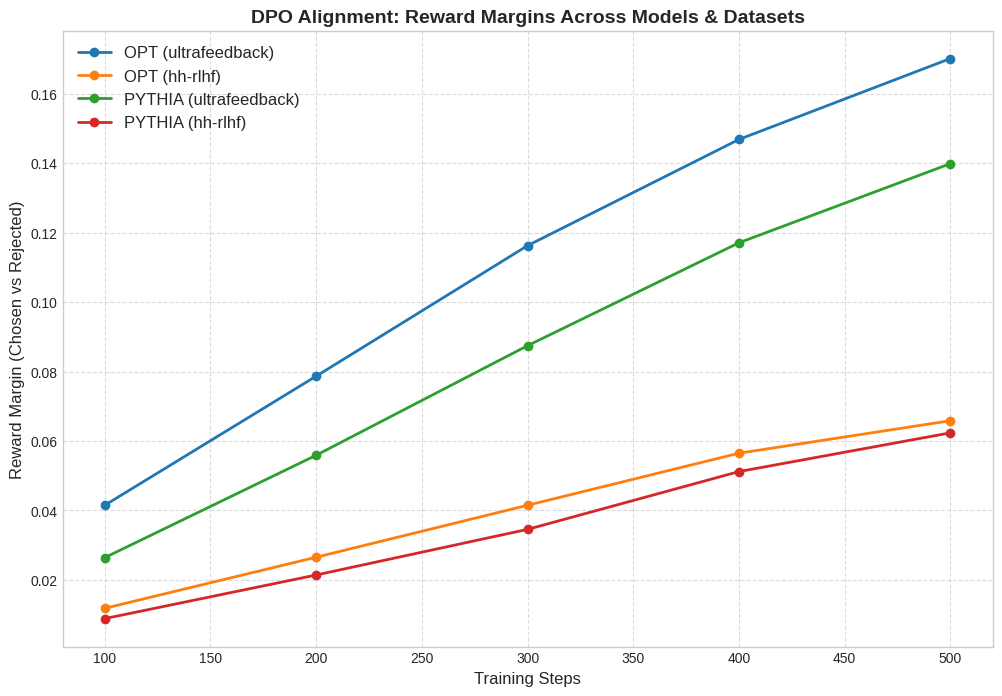


Graph successfully saved to /content/drive/MyDrive/RLHF_Project/margin_comparison_2x2.png


In [7]:
def plot_2x2_margins(base_dir=BASE_DIR):
    plt.figure(figsize=(12, 8))
    plt.style.use('seaborn-v0_8-whitegrid')

    combinations = [
        ("opt", "ultrafeedback", '#1f77b4'),    # Blue
        ("opt", "hh-rlhf", '#ff7f0e'),          # Orange
        ("pythia", "ultrafeedback", '#2ca02c'), # Green
        ("pythia", "hh-rlhf", '#d62728')        # Red
    ]

    found_any = False

    for model_key, ds_key, color in combinations:
        # Base directory for this specific run
        run_dir = os.path.join(base_dir, f"{model_key}_dpo_{ds_key}_results")

        # 1. Search in the root folder
        possible_paths = [os.path.join(run_dir, "trainer_state.json")]

        # 2. Search inside all checkpoint subfolders
        possible_paths.extend(glob.glob(os.path.join(run_dir, "checkpoint-*", "trainer_state.json")))

        # 3. Check the final model output folder just in case
        possible_paths.append(os.path.join(base_dir, f"{model_key}_dpo_{ds_key}_final", "trainer_state.json"))

        # Find the first path that actually exists
        state_path = next((p for p in possible_paths if os.path.exists(p)), None)

        if not state_path:
            print(f"Missing logs for {model_key.upper()} + {ds_key}. Are you sure it finished training?")
            continue

        with open(state_path, "r") as f:
            state = json.load(f)

        steps, margins = [], []
        for log in state.get("log_history", []):
            if "eval_rewards/margins" in log:
                steps.append(log["step"])
                margins.append(log["eval_rewards/margins"])

        if steps and margins:
            plt.plot(steps, margins, marker='o', linewidth=2, color=color, label=f'{model_key.upper()} ({ds_key})')
            found_any = True

    if found_any:
        plt.title("DPO Alignment: Reward Margins Across Models & Datasets", fontsize=14, fontweight='bold')
        plt.xlabel("Training Steps", fontsize=12)
        plt.ylabel("Reward Margin (Chosen vs Rejected)", fontsize=12)
        plt.legend(fontsize=12)
        plt.grid(True, linestyle='--', alpha=0.7)
        plot_path = os.path.join(base_dir, "margin_comparison_2x2.png")
        plt.savefig(plot_path, dpi=300, bbox_inches='tight')
        plt.show()
        print(f"\nGraph successfully saved to {plot_path}")
    else:
        print("\nNo data could be plotted.")

plot_2x2_margins()

In [8]:
def calculate_perplexity(model, tokenizer):
    """Calculates perplexity on a subset of WikiText-2."""
    test = load_dataset("wikitext", "wikitext-2-raw-v1", split="test[:50]")
    encodings = tokenizer("\n\n".join(test["text"]), return_tensors="pt")

    max_length = model.config.max_position_embeddings
    stride = 512
    seq_len = encodings.input_ids.size(1)

    nlls = []
    for i in range(0, seq_len, stride):
        begin_loc = max(i + stride - max_length, 0)
        end_loc = min(i + stride, seq_len)
        trg_len = end_loc - i
        input_ids = encodings.input_ids[:, begin_loc:end_loc].to("cuda" if torch.cuda.is_available() else "cpu")
        target_ids = input_ids.clone()
        target_ids[:, :-trg_len] = -100

        with torch.no_grad():
            outputs = model(input_ids, labels=target_ids)
            neg_log_likelihood = outputs.loss

        nlls.append(neg_log_likelihood * trg_len)

    return torch.exp(torch.stack(nlls).sum() / end_loc).item()

# Evaluation Prompts
qual_prompt = "What are the benefits of a healthy diet?"
verbosity_prompts = [
    "What are the benefits of regular exercise?",
    "Explain the importance of sleep.",
    "How do you make a good cup of coffee?"
]
tax_prompts = [
    "Logic: If I have 3 apples, eat 1, and buy 5 more, how many apples do I have?",
    "Fact: What is the capital city of Australia?"
]

gen_kwargs = {
    "max_new_tokens": 75,
    "do_sample": True,
    "temperature": 0.7,
    "top_p": 0.9,
    "repetition_penalty": 1.15,
    "return_full_text": False
}

eval_results = {}

for model_key, model_id in MODELS.items():
    eval_results[model_key] = {}
    tokenizer = AutoTokenizer.from_pretrained(model_id)
    tokenizer.pad_token = tokenizer.eos_token

    sft_path = os.path.join(BASE_DIR, f"{model_key}_sft_final_model")

    variants = {
        "SFT Baseline": sft_path,
        "RLHF (UltraFeedback)": os.path.join(BASE_DIR, f"{model_key}_rlhf_ultrafeedback_final"),
        "RLHF (HH-RLHF)": os.path.join(BASE_DIR, f"{model_key}_rlhf_hh-rlhf_final")
    }

    for var_name, path in variants.items():
        print(f"\n[{model_key.upper()} | {var_name}] Loading and evaluating...")
        if not os.path.exists(path):
            print(f" -> Skipping: Model not found at {path}")
            continue

        # Safely load base or merged LoRA model
        if "SFT Baseline" in var_name:
            model = AutoModelForCausalLM.from_pretrained(path, device_map="auto")
        else:
            base = AutoModelForCausalLM.from_pretrained(sft_path, device_map="auto")
            model = PeftModel.from_pretrained(base, path).merge_and_unload()

        pipe = pipeline("text-generation", model=model, tokenizer=tokenizer, device_map="auto")

        # 1. Perplexity
        ppl = calculate_perplexity(model, tokenizer)

        # 2. Qualitative
        fmt_qual = f"### Instruction:\n{qual_prompt}\n\n### Response:\n"
        qual_out = pipe(fmt_qual, **gen_kwargs)[0]['generated_text'].strip()

        # 3. Verbosity Bias
        v_lengths = []
        for vp in verbosity_prompts:
            fmt_v = f"### Instruction:\n{vp}\n\n### Response:\n"
            v_lengths.append(len(pipe(fmt_v, **gen_kwargs)[0]['generated_text'].strip().split()))
        avg_v = sum(v_lengths) / len(v_lengths)

        # 4. Alignment Tax
        tax_outputs = []
        for tp in tax_prompts:
            fmt_t = f"### Instruction:\n{tp}\n\n### Response:\n"
            tax_outputs.append((tp, pipe(fmt_t, **gen_kwargs)[0]['generated_text'].strip()))

        # Store results
        eval_results[model_key][var_name] = {
            "ppl": ppl, "qual": qual_out, "verbosity": avg_v, "tax": tax_outputs
        }

        # CRITICAL: Free up VRAM for the next model
        del model
        del pipe
        gc.collect()
        torch.cuda.empty_cache()

# --- PRINT FORMATTED REPORT ---
print("\n" + "="*60)
print(" FINAL 2x2 GRID EVALUATION REPORT ")
print("="*60)

for model_key, variants in eval_results.items():
    print(f"\n{'='*20} {model_key.upper()} ARCHITECTURE {'='*20}")

    print("\n--- PERPLEXITY SCORES ---")
    for var_name, data in variants.items():
        print(f"{var_name}: {data['ppl']:.2f}")

    print("\n--- VERBOSITY BIAS (Avg Words) ---")
    for var_name, data in variants.items():
        print(f"{var_name}: {data['verbosity']:.1f}")

    print("\n--- QUALITATIVE: HEALTHY DIET ---")
    for var_name, data in variants.items():
        print(f"[{var_name}]: {data['qual']}\n")

    print("--- ALIGNMENT TAX: FACT & LOGIC ---")
    for var_name, data in variants.items():
        print(f"\n[{var_name}]")
        for prompt, response in data['tax']:
            print(f" Q: {prompt}\n A: {response}")

/usr/local/lib/python3.12/dist-packages/transformers/tokenization_utils_base.py:1601: FutureWarning: `clean_up_tokenization_spaces` was not set. It will be set to `True` by default. This behavior will be depracted in transformers v4.45, and will be then set to `False` by default. For more details check this issue: https://github.com/huggingface/transformers/issues/31884
  warnings.warn(



[OPT | SFT Baseline] Loading and evaluating...


README.md: 0.00B [00:00, ?B/s]

wikitext-2-raw-v1/test-00000-of-00001.pa(…):   0%|          | 0.00/733k [00:00<?, ?B/s]

wikitext-2-raw-v1/train-00000-of-00001.p(…):   0%|          | 0.00/6.36M [00:00<?, ?B/s]

...

Generating train split:   0%|          | 0/36718 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/3760 [00:00<?, ? examples/s]


[OPT | RLHF (UltraFeedback)] Loading and evaluating...

[OPT | RLHF (HH-RLHF)] Loading and evaluating...


/usr/local/lib/python3.12/dist-packages/transformers/tokenization_utils_base.py:1601: FutureWarning: `clean_up_tokenization_spaces` was not set. It will be set to `True` by default. This behavior will be depracted in transformers v4.45, and will be then set to `False` by default. For more details check this issue: https://github.com/huggingface/transformers/issues/31884
  warnings.warn(



[PYTHIA | SFT Baseline] Loading and evaluating...

[PYTHIA | RLHF (UltraFeedback)] Loading and evaluating...

[PYTHIA | RLHF (HH-RLHF)] Loading and evaluating...

 FINAL 2x2 GRID EVALUATION REPORT 

==================== OPT ARCHITECTURE ====================

--- PERPLEXITY SCORES ---
SFT Baseline: 21.94
RLHF (UltraFeedback): 21.87
RLHF (HH-RLHF): 21.95

--- VERBOSITY BIAS (Avg Words) ---
SFT Baseline: 62.7
RLHF (UltraFeedback): 64.7
RLHF (HH-RLHF): 63.7

--- QUALITATIVE: HEALTHY DIET ---
[SFT Baseline]: A healthy diet is an important part of any healthy lifestyle. It includes foods that contain fiber, antioxidants, vitamins and minerals, carbohydrates, fats, proteins, carbohydrates, fruits and vegetables, whole grains, nuts, seeds, fish, whole grains, and other sources of protein, as well as dairy products such as milk, cheese, yogurt, and whole grains. Additionally, regular

[RLHF (UltraFeedback)]: A healthy diet can be beneficial for many people, including weight management, heart h